<a href="https://colab.research.google.com/github/luciusartor1uscastus/python-practice-algos/blob/master/hw_5_borisov_f_o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os
import struct
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
import kagglehub

path = kagglehub.dataset_download("hojjatk/mnist-dataset")
ROOT = Path(path)

def read_idx_images(path):
    with open(path, 'rb') as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        assert magic == 2051
        data = np.frombuffer(f.read(), dtype=np.uint8)
        data = data.reshape(n, rows * cols)
    return data.astype(np.float32)

def read_idx_labels(path):
    with open(path, 'rb') as f:
        magic, n = struct.unpack(">II", f.read(8))
        assert magic == 2049
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.astype(np.int64)

def find_file(name, root_dir=ROOT):
    root = Path(root_dir)
    p = root / name
    if p.exists():
        return p
    for sub in root.rglob(name):
        return sub
    raise FileNotFoundError(f"Файл {name} не найден")

train_images_path = find_file("train-images.idx3-ubyte")
train_labels_path = find_file("train-labels.idx1-ubyte")
test_images_path = find_file("t10k-images.idx3-ubyte")
test_labels_path = find_file("t10k-labels.idx1-ubyte")

X_train_full = read_idx_images(train_images_path)
y_train_full = read_idx_labels(train_labels_path)
X_test = read_idx_images(test_images_path)
y_test = read_idx_labels(test_labels_path)

X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

subset_idx = np.random.choice(len(X_train_full), 15000, replace=False)
X_train = X_train_full[subset_idx]
y_train = y_train_full[subset_idx]

Using Colab cache for faster access to the 'mnist-dataset' dataset.


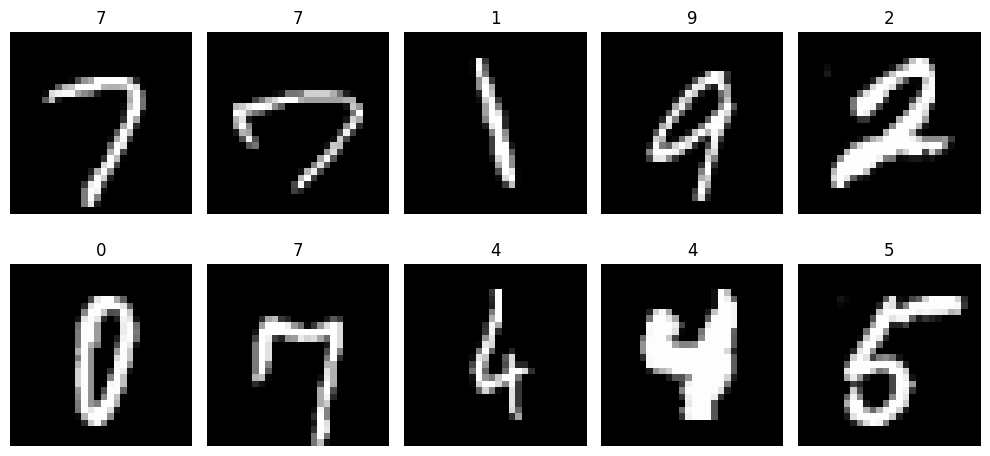

In [4]:
unique, counts = np.unique(y_train, return_counts=True)
balance_df = pd.DataFrame({'Class': unique, 'Count': counts})

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(str(y_train[i]))
    ax.axis('off')
plt.tight_layout()
plt.show()

In [5]:
models = {
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "DecisionTree_depth15": DecisionTreeClassifier(max_depth=15, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "HistGB": HistGradientBoostingClassifier(random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = accuracy_score(y_test, y_pred)

results_df = pd.DataFrame(list(results.items()), columns=['Model', 'Accuracy'])
display(results_df)

,Model,Accuracy
0,DecisionTree,0.8307
1,DecisionTree_depth15,0.8333
2,RandomForest,0.9544
3,HistGB,0.9622
